218
17.5
8
1.71
5
0.2268928027592628
3
-0.3246312408709453
3
-2.4242623310201012
12920
-3.6128315516282394
66
0.5515240436302081
5
1428340
3
54


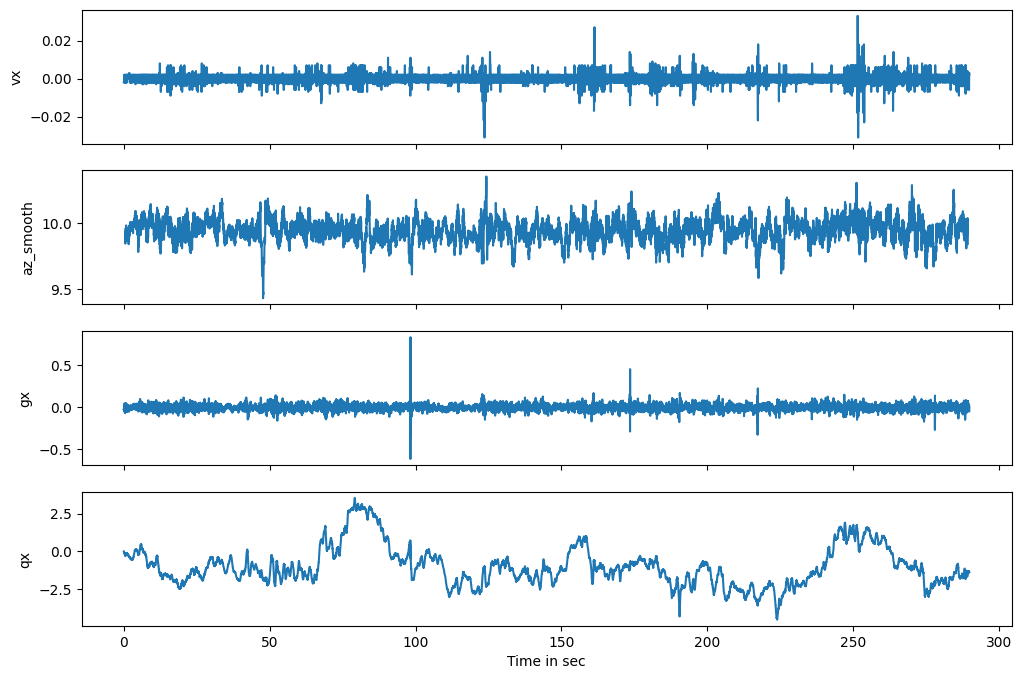

In [1]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import statistics

desktop_path = r"C:\Users\stratklar\Documents\Markus\ASA\Indien\Testdaten_Rikscha\pothole_compact_4"

imu_dir = os.path.join(desktop_path,"extracted_imu", "imu_data_v3.csv")
odom_dir = os.path.join(desktop_path,"extracted_odom", "odom_data_v3.csv")

imu_data = pd.read_csv(imu_dir)
odom_data = pd.read_csv(odom_dir)

imu = imu_data[["Timestamp", "index", "az", "gx"]]
odom = odom_data[["Timestamp", "vx"]]

df = pd.merge_asof(
    odom.sort_values("Timestamp"),
    imu.sort_values("Timestamp"),
    on="Timestamp",
    direction="nearest",
    tolerance=20000000
)

#t_0 = df[df["index"] == 0]
#t0 = t_0["Timestamp"][0]
t0 = df["Timestamp"].min()
df["Time_ns"] = df["Timestamp"] - t0
df["Time"] = df["Time_ns"] / 1000000000
df["qx_from_gx"] = df["gx"].cumsum()   
df["az_smooth"] = df["az"].rolling(window=51, center=True).mean()
#df["az_smooth/vx"] = (df["az_smooth"] - df["az_smooth"].mean()) / (df["vx"].abs() + 0.001)

fig, ax = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
ax[0].plot(df["Time"], df["vx"], label="speed")
ax[1].plot(df["Time"], df["az_smooth"], label="linear acceleration")
ax[2].plot(df["Time"], df["gx"], label="angular velocity")
#ax[3].plot(df["Timestamp"], df["az_smooth/vx"], label="linear acceleration per speed")
ax[3].plot(df["Time"], df["qx_from_gx"], label="rotation_x")

ax[0].set_ylabel("vx")
ax[1].set_ylabel("az_smooth")
ax[2].set_ylabel("gx")
#ax[3].set_ylabel("az/vx")
ax[3].set_ylabel("qx")
ax[3].set_xlabel("Time in sec")

#anomalies = df.loc[df['az'].abs().nlargest(3).index]["Time"]
#print(anomalies)

sorted_by_az = df.sort_values('az', key=lambda x: x.abs(), ascending=False)

anomalies_indices = []

for idx, row in sorted_by_az.iterrows():
    if all(abs(row['Time'] - df.loc[i, 'Time']) >= 2 for i in anomalies_indices):
        anomalies_indices.append(idx)

    if len(anomalies_indices) == 7:
        break

anomalies = df.loc[anomalies_indices]
#print(anomalies)

#========================================================================

sorted_by_gx = df.sort_values('gx', key=lambda x: x.abs(), ascending=False)

anomalies_indices = []

for idx, row in sorted_by_gx.iterrows():
    if all(abs(row['Time'] - df.loc[i, 'Time']) >= 2 for i in anomalies_indices):
        anomalies_indices.append(idx)

    if len(anomalies_indices) == 7:
        break

anomalies = df.loc[anomalies_indices]
#print(anomalies)

#========================================================================

sorted_by_qx = df.sort_values('qx_from_gx', key=lambda x: x.abs(), ascending=False)

anomalies_indices = []

for idx, row in sorted_by_qx.iterrows():
    if all(abs(row['Time'] - df.loc[i, 'Time']) >= 2 for i in anomalies_indices):
        anomalies_indices.append(idx)

    if len(anomalies_indices) == 7:
        break

anomalies = df.loc[anomalies_indices]
#print(anomalies)

#========================================================================

sorted_by_az_smooth = df.sort_values('az_smooth', key=lambda x: x.abs(), ascending=False)

anomalies_indices = []

for idx, row in sorted_by_az_smooth.iterrows():
    if all(abs(row['Time'] - df.loc[i, 'Time']) >= 2 for i in anomalies_indices):
        anomalies_indices.append(idx)

    if len(anomalies_indices) == 7:
        break

anomalies = df.loc[anomalies_indices]
#print(anomalies)

print("=============================================")

count2 = 0
for i in [218]:
    print(i)
    az_i_max = df[abs(df["Time"] - i) <= 2]["az"].max()
    print(az_i_max)
    print(len(df[df["az"] > az_i_max]))
    az_i_min = df[abs(df["Time"] - i) <= 2]["az"].min()
    print(az_i_min)
    print(len(df[df["az"] < az_i_min]))

    gx_i_max = df[abs(df["Time"] - i) <= 2]["gx"].max()
    print(gx_i_max)
    print(len(df[df["gx"] > gx_i_max]))
    gx_i_min = df[abs(df["Time"] - i) <= 2]["gx"].min()
    print(gx_i_min)
    print(len(df[df["gx"] < gx_i_min]))

    qx_i_max = df[abs(df["Time"] - i) <= 2]["qx_from_gx"].max()
    print(qx_i_max)
    print(len(df[df["qx_from_gx"] > qx_i_max]))
    qx_i_min = df[abs(df["Time"] - i) <= 2]["qx_from_gx"].min()
    print(qx_i_min)
    print(len(df[df["qx_from_gx"] < qx_i_min]))
    print(gx_i_max - gx_i_min)
    
    rank_az_range = 0
    latest_az = -2
    for row1 in df.itertuples(index = False):
        #if row1.Time > latest_az + 2:
        df_tmp = df[(df["Time"] > row1.Time) & (df["Time"] < row1.Time + 2)]
        for row2 in df_tmp.itertuples(index = False):
            if abs(row1.az - row2.az) > az_i_max - az_i_min and row1.Time > latest_az + 2:
                rank_az_range = rank_az_range + 1
                latest_az = row1.Time
    print(rank_az_range)
    
    rank_gx_range = 0 #number of bigger ranges
    latest_gx = -2
    for row1 in df.itertuples(index = False):
        df_tmp = df[(df["Time"] > row1.Time) & (df["Time"] < row1.Time + 2)]
        for row2 in df_tmp.itertuples(index = False):
            count2 += 1
            if abs(row1.gx - row2.gx) > gx_i_max - gx_i_min and row1.Time > latest_gx + 2:
                rank_gx_range = rank_gx_range + 1
                latest_gx = row1.Time
    print(count2)
    print(rank_gx_range)
    
    rank_qx_range = 0
    latest_qx = -2
    for row1 in df.itertuples(index = False):
        df_tmp = df[(df["Time"] > row1.Time) & (df["Time"] < row1.Time + 2)]
        for row2 in df_tmp.itertuples(index = False):
            if abs(row1.qx_from_gx - row2.qx_from_gx) > qx_i_max - qx_i_min and row1.Time > latest_qx + 2:
                rank_qx_range = rank_qx_range + 1
                latest_qx = row1.Time
    print(rank_qx_range)
    
    